In [1]:
# load dataset
# scaler, X_scaled
# tts
# evaluate fn.
# knn before PCA, save in res
# PCA, cumulative, explained_variance_ratio_, plot
# PCA with 2 components, scatter plot, X_pca[:, 0] X_pca[:, 1]
# X=X_pca, KNN on 2 PCA, store in res
# comparison from res

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier

In [3]:
df = pd.read_csv("Wine.csv")

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop("Customer_Segment", axis=1))

In [5]:
X = X_scaled
y = df["Customer_Segment"]

print("X shape:", X.shape)
print("Classes:", y.unique())

X shape: (178, 13)
Classes: [1 2 3]


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (142, 13)  Test: (36, 13)


In [7]:
def evaluate(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=model.classes_).plot()
    
    plt.title("Confusion Matrix - " + name)
    plt.show()

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    }
    
    print("=====", name, "=====")
    
    for metric, value in list(result.items())[1:]:
        print(f"{metric:10s}: {value:.4f}")
    return result

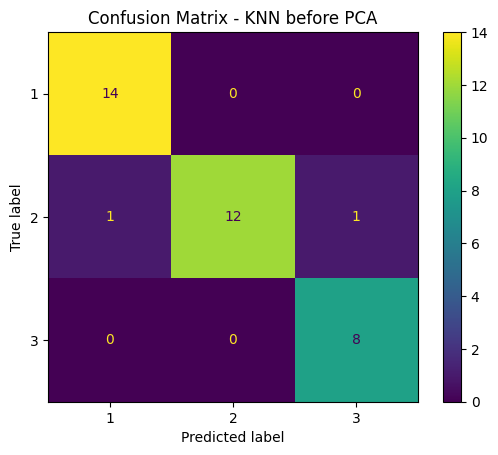

===== KNN before PCA =====
Accuracy  : 0.9444
Precision : 0.9494
Recall    : 0.9444
F1-Score  : 0.9436
{'Model': 'KNN before PCA', 'Accuracy': 0.9444444444444444, 'Precision': 0.9493827160493827, 'Recall': 0.9444444444444444, 'F1-Score': 0.9436036129748098}


In [8]:
# KNN before PCA

results = []
results.append(evaluate("KNN before PCA", KNeighborsClassifier(n_neighbors=5), X_train, X_test, y_train, y_test))
print(results[0])

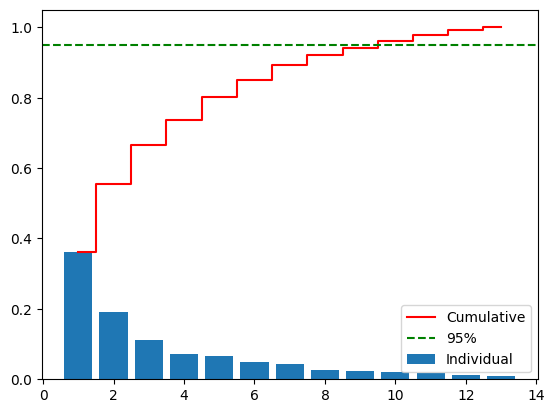

In [9]:
# PCA with variance

pca_full = PCA().fit(X_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

plt.bar(range(1, 14), pca_full.explained_variance_ratio_, label="Individual")
plt.step(range(1, 14), cumulative, where="mid", color="red", label="Cumulative")
plt.axhline(0.95, color="green", linestyle="--", label="95%")

plt.legend()
plt.show()

Features before PCA: (178, 13)
Features after PCA : (178, 2)
Variance kept by PC1, PC2: [0.362 0.192]
Total variance kept: 55.41 %


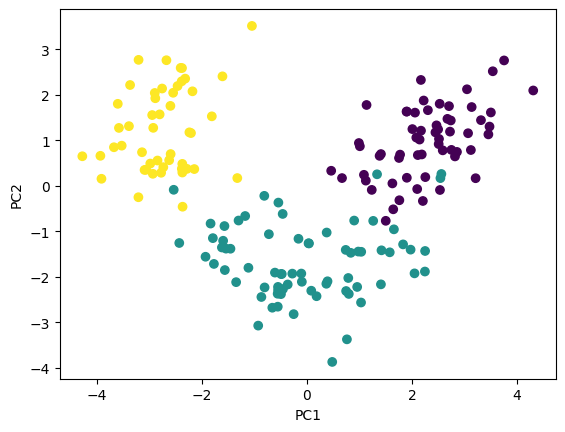

In [10]:
# PCA with 2 components

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Features before PCA:", X_scaled.shape)
print("Features after PCA :", X_pca.shape)
print("Variance kept by PC1, PC2:", pca.explained_variance_ratio_.round(3))
print("Total variance kept:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

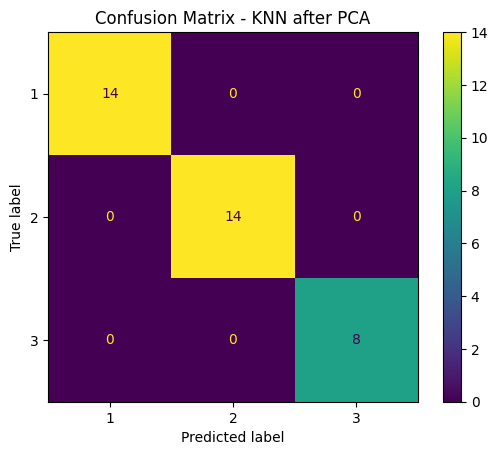

===== KNN after PCA =====
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


In [11]:
# KNN after 2 PCA

X = X_pca
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

results.append(evaluate("KNN after PCA", KNeighborsClassifier(n_neighbors=5), X_train, X_test, y_train, y_test))

                Accuracy  Precision  Recall  F1-Score
Model                                                
KNN before PCA    0.9444     0.9494  0.9444    0.9436
KNN after PCA     1.0000     1.0000  1.0000    1.0000


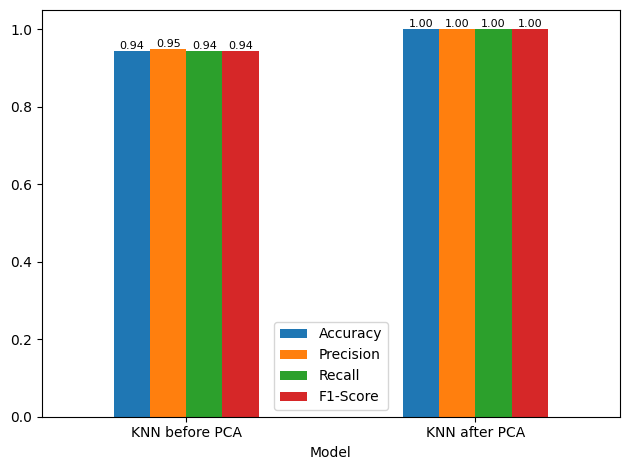

In [12]:
results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))

ax = results_df.plot(kind="bar", rot=0, legend=True)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# predict wine segment from user input (press Enter to use the average value)

feature_cols = df.drop("Customer_Segment", axis=1).columns
user = {}
for col in feature_cols:
    val = input(f"{col} [{df[col].mean():.2f}]: ").strip()
    user[col] = float(val) if val else df[col].mean()
user_scaled = scaler.transform(pd.DataFrame([user]))
user_pca = pca.transform(user_scaled)

# final models trained on all the data
knn_before = KNeighborsClassifier(n_neighbors=5).fit(X_scaled, y)
knn_after = KNeighborsClassifier(n_neighbors=5).fit(X_pca, y)

print("\nInput:", user)
print("PC1, PC2:", user_pca.round(3)[0])
print("KNN before PCA -> Segment", knn_before.predict(user_scaled)[0])
print("KNN after PCA  -> Segment", knn_after.predict(user_pca)[0])